## Linear Regression with one variable

- Learn to implement the model $f_{w,b}$ for linear regression with one variable

## Tools
In this lab you will make use of: 
- NumPy, a popular library for scientific computing
- Matplotlib, a popular library for plotting data

## Notation

Here is a summary of some of the notation you will encounter.

| Notation | Description | Python |
|:---------|:------------|:------|
| `a` | Scalar (non-bold) | |
| **a** | Vector (bold) | |
| **Regression** | | |
| **x** | Training example feature values (e.g. size in 1000 sq ft) | `x_train` |
| **y** | Training example targets (e.g. price in $1000s) | `y_train` |
| `x(i)`, `y(i)` | i-th training example | `x_i`, `y_i` |
| `m` | Number of training examples | `m` |
| `w` | Model parameter: weight | `w` |
| `b` | Model parameter: bias | `b` |
| `f(x) = wx + b` | Model prediction | `f_wb` |

In [1]:
import math, copy
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('./deeplearning.mplstyle')
from lab_utils_uni import plt_house_x, plt_contour_wgrad, plt_divergence, plt_gradients,plt_intuition, soup_bowl


# Problem Statement

As in the lecture, you will use the motivating example of housing price prediction.  
This lab will use a simple data set with only two data points - a house with 1000 square feet(sqft) sold for \\$300,000 and a house with 2000 square feet sold for \\$500,000. These two points will constitute our *data or training set*. In this lab, the units of size are 1000 sqft and the units of price are 1000s of dollars.

| Size (1000 sqft)     | Price (1000s of dollars) |
| -------------------| ------------------------ |
| 1.0               | 300                      |
| 2.0               | 500                      |

You would like to fit a linear regression model (shown above as the blue straight line) through these two points, so you can then predict price for other houses - say, a house with 1200 sqft.


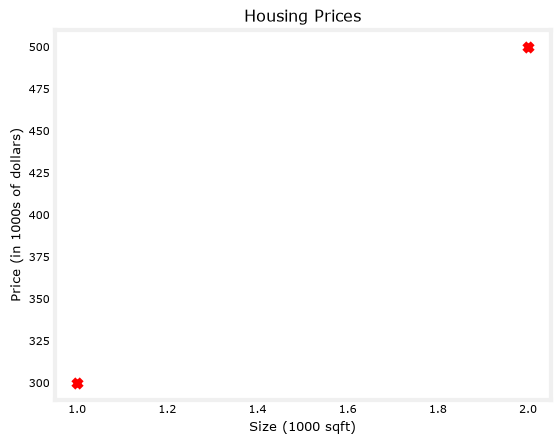

In [2]:
#define two inputs/ training examples  
x_train = np.array([1.0,2.0])
y_train = np.array([300,500])

#define m = number of training examples
m=len(x_train) #or x_train.shape[0]

#plot the data points
plt.scatter(x_train, y_train, marker='x', c='r')
plt.title("Housing Prices")
plt.ylabel('Price (in 1000s of dollars)')
plt.xlabel('Size (1000 sqft)')
plt.show()

## How will you predict for new values?

You need to find a linear equation f_wb(x)= w*x +b that for any x gives the correct y. Since we already have x and f_wb(x) (which is y), we need to find w and b. But how?

> For each Trial, we will calculate the cost function (or total error ) and assess if the output is accurate mathematically

### 1. Brute Force 
Take any random values for w and b and hit and trial until it satisfy.

In [3]:
#Find Error Rate using Cost function

def compute_cost(x,y,w,b):
    m=x.shape[0]

    cost_sum=0
    for i in range(m):
        f_wb= w*x[i]+b
        cost= (f_wb-y[i])**2
        cost_sum= cost_sum + cost
    
    total_cost= cost_sum /(2*m)

    return total_cost

##### Trial 1

Error rate for y_train: 12500.0


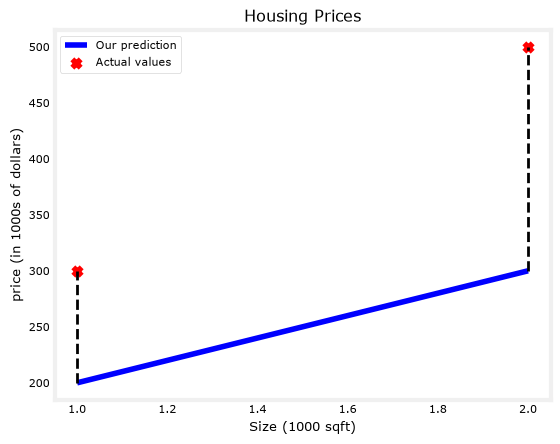

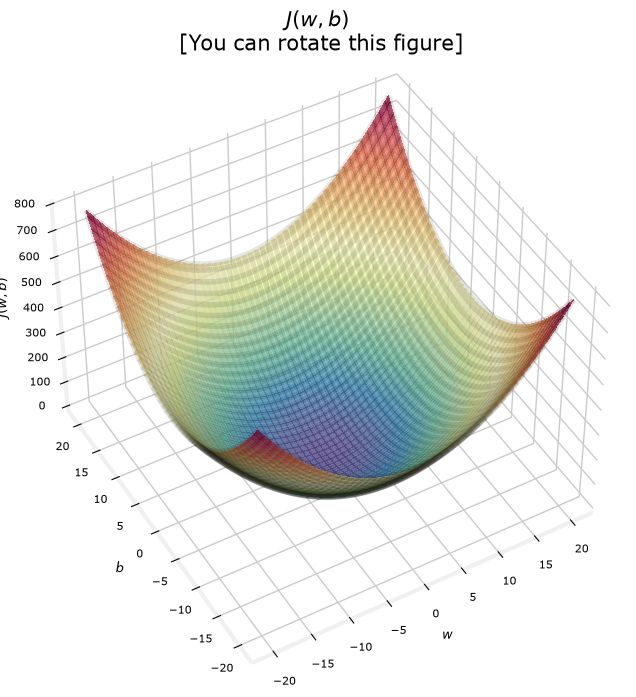

In [4]:
w=100
b=100

#predict values for given x_train
f_wb= np.zeros(m)
for i in range(m):
    f_wb[i]= w*x_train[i] +b


print(f"Error rate for y_train: {compute_cost(x_train, y_train, w, b)}")


#plot and visualize
plt.plot(x_train, f_wb, c='b', label='Our prediction')
plt.scatter(x_train, y_train, marker='x', c='r', label='Actual values')

# Draw error lines
for i in range(m):
    plt.plot([x_train[i], x_train[i]],
             [f_wb[i], y_train[i]],
             'k--',
             linewidth=2)
    
plt.title('Housing Prices')
plt.ylabel('price (in 1000s of dollars)')
plt.xlabel('Size (1000 sqft)')

plt.legend()
plt.show()

soup_bowl()

#### Trial 2

Error rate for y_train: 0.0


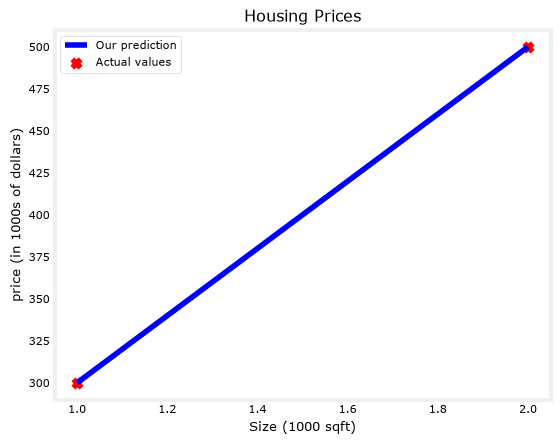

In [5]:
w=200
b=100

#predict values for given x_train
f_wb= np.zeros(m)
for i in range(m):
    f_wb[i]= w*x_train[i] +b

print(f"Error rate for y_train: {compute_cost(x_train, y_train, w, b)}")

#plot and visualize
plt.plot(x_train, f_wb, c='b', label='Our prediction')
plt.scatter(x_train, y_train, marker='x', c='r', label='Actual values')

plt.title('Housing Prices')
plt.ylabel('price (in 1000s of dollars)')
plt.xlabel('Size (1000 sqft)')

plt.legend()
plt.show()

#### Prediction

340 thousand dolllars


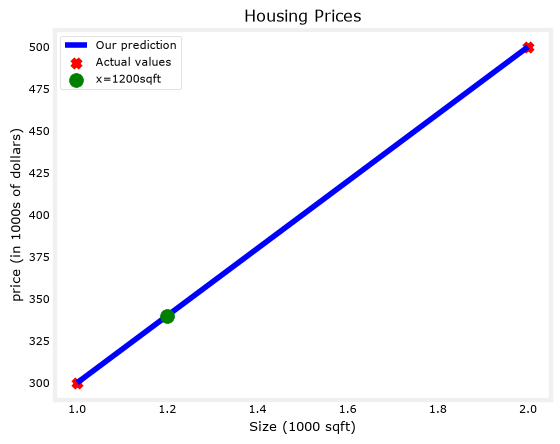

In [6]:
#predict house price for x=1200 sqft

cost_1200sqft= w*1.2 + b
print(f"{cost_1200sqft:.0f} thousand dolllars")

#plot and visualize
plt.plot(x_train, f_wb, c='b', label='Our prediction')
plt.scatter(x_train, y_train, marker='x', c='r', label='Actual values')

#prediction
x_mark=1.2
y_mark=cost_1200sqft
plt.scatter(x_mark, y_mark, c='green', s=100, zorder=5, label='x=1200sqft')


plt.title('Housing Prices')
plt.ylabel('price (in 1000s of dollars)')
plt.xlabel('Size (1000 sqft)')

plt.legend()
plt.show()

#### 2. Gradient Descent 
Given the cost function J(w,b), we alter the values of w and b to minimize J(w,b)


$$\begin{align*} \text{repeat}&\text{ until convergence:} \; \lbrace \newline
\;  w &= w -  \alpha \frac{\partial J(w,b)}{\partial w} \tag{3}  \; \newline 
 b &= b -  \alpha \frac{\partial J(w,b)}{\partial b}  \newline \rbrace
\end{align*}$$
where, parameters $w$, $b$ are updated simultaneously.  
The gradient is defined as:
$$
\begin{align}
\frac{\partial J(w,b)}{\partial w}  &= \frac{1}{m} \sum\limits_{i = 0}^{m-1} (f_{w,b}(x^{(i)}) - y^{(i)})x^{(i)} \tag{4}\\
  \frac{\partial J(w,b)}{\partial b}  &= \frac{1}{m} \sum\limits_{i = 0}^{m-1} (f_{w,b}(x^{(i)}) - y^{(i)}) \tag{5}\\
\end{align}
$$

Here *simultaniously* means that you calculate the partial derivatives for all the parameters before updating any of the parameters.

In [7]:
def compute_gradient(x,y, w, b):
    """Computes the gradient for linear regression
    Input:  x, y (ndarray (m,))
            w, b (scalar)
    Returns:
            dj_dw , dj_db (scalar)
    """

    m= x.shape[0]
    cost_w=0
    cost_b =0

    for i in range(m):
        j_wb= w*x[i] + b
        cost_w = cost_w + (j_wb - y[i]) * x[i]
        cost_b = cost_b + (j_wb - y[i])
        
    dj_dw=(cost_w)/m
    dj_db=(cost_b)/m

    return dj_db, dj_dw


In [8]:
def gradient_descent(x,y,w_input,b_input,alpha,num_iterations):
    
    cost_history=[]
    p_hist=[] #for plotting onto contour plot

    w = w_input
    b= b_input
    
    for i in range(1,num_iterations+1):

        dj_db, dj_dw= compute_gradient(x,y,w,b)

        w = w - alpha* dj_dw
        b = b - alpha* dj_db
        
        cost_history.append(compute_cost(x,y,w, b))
        p_hist.append([w,b])


        print(f"Iteration {i-1} : w={w} , b= {b} , dj_dw= {dj_dw} , dj_db = {dj_db} , cost = {cost_history[i-1]} ")
    
    
    return  w, b, cost_history, p_hist


In [10]:
# initialize parameters
w_init = 0
b_init = 0
# Load our data set
x_train = np.array([1.0, 2.0])   #features
y_train = np.array([300.0, 500.0])   #target value
# some gradient descent settings
iterations = 10000
tmp_alpha = 1.0e-2
# run gradient descent
w_final, b_final , cost_history, p_hist = gradient_descent(x_train ,y_train, w_init, b_init, tmp_alpha,iterations)
print(f"(w,b) found by gradient descent: ({w_final:8.4f},{b_final:8.4f})")

Iteration 0 : w=6.5 , b= 4.0 , dj_dw= -650.0 , dj_db = -400.0 , cost = 79274.8125 
Iteration 1 : w=12.7775 , b= 7.862500000000001 , dj_dw= -627.75 , dj_db = -386.25 , cost = 73935.3097265625 
Iteration 2 : w=18.840125 , b= 11.5922125 , dj_dw= -606.2625 , dj_db = -372.97125 , cost = 68955.50943163194 
Iteration 3 : w=24.6952386875 , b= 15.1936885 , dj_dw= -585.51136875 , dj_db = -360.1476 , cost = 64311.1797016098 
Iteration 4 : w=30.3499523928125 , b= 18.6713230346875 , dj_dw= -565.4713705312499 , dj_db = -347.76345346874996 , cost = 59979.72104335757 
Iteration 5 : w=35.81113373747188 , b= 22.02936051844844 , dj_dw= -546.1181344659375 , dj_db = -335.8037483760938 , cost = 55940.056413659375 
Iteration 6 : w=41.08541498625836 , b= 25.271899907201878 , dj_dw= -527.4281248786476 , dj_db = -324.25393887534375 , cost = 52172.52865702032 
Iteration 7 : w=46.17920111299387 , b= 28.402899683335985 , dj_dw= -509.3786126735513 , dj_db = -313.0999776134106 , cost = 48658.804852726775 
Iteration 

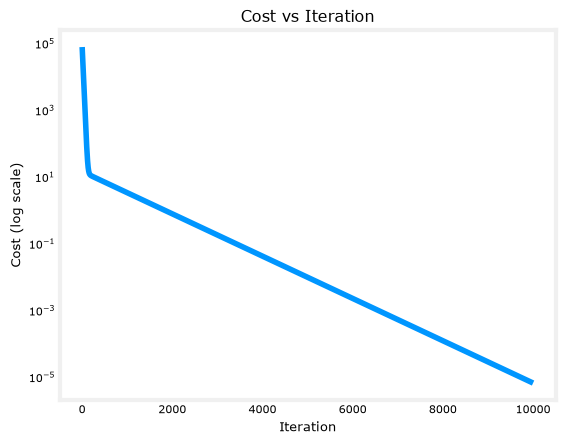

In [11]:
plt.plot(cost_history)
plt.yscale("log")
plt.xlabel("Iteration")
plt.ylabel("Cost (log scale)")
plt.title("Cost vs Iteration")
plt.show()

#### Prediction 

In [12]:
print(f"1000 sqft house prediction {w_final*1.0 + b_final:0.1f} Thousand dollars")
print(f"1200 sqft house prediction {w_final*1.2 + b_final:0.1f} Thousand dollars")
print(f"2000 sqft house prediction {w_final*2.0 + b_final:0.1f} Thousand dollars")

1000 sqft house prediction 300.0 Thousand dollars
1200 sqft house prediction 340.0 Thousand dollars
2000 sqft house prediction 500.0 Thousand dollars


### Progress of Gradient Descent

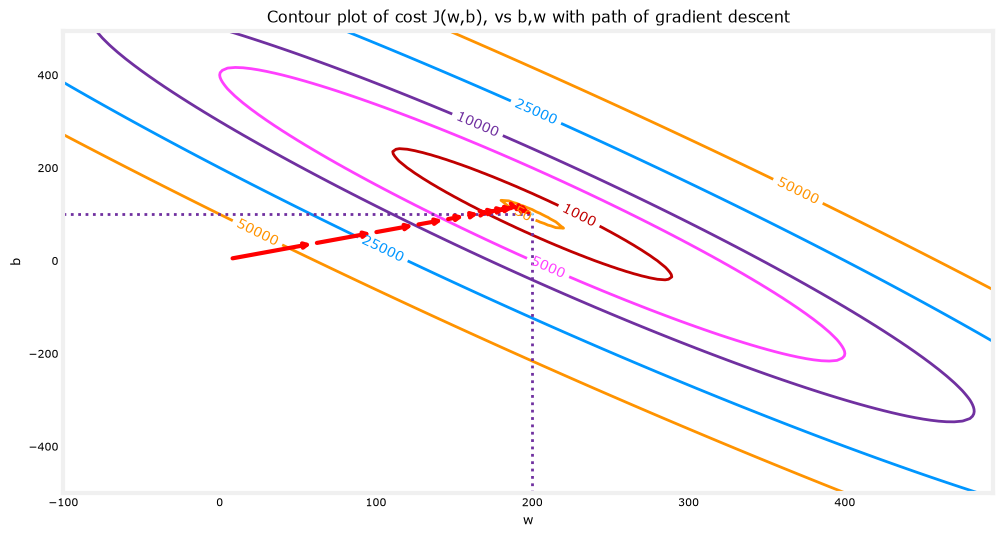

In [13]:
fig, ax = plt.subplots(1,1, figsize=(12, 6))
plt_contour_wgrad(x_train, y_train, p_hist, ax)

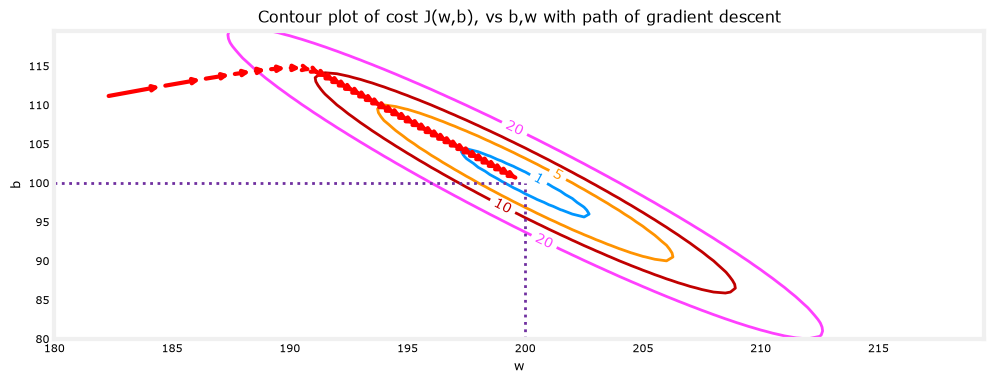

In [14]:
fig, ax = plt.subplots(1,1, figsize=(12, 4))
plt_contour_wgrad(x_train, y_train, p_hist, ax, w_range=[180, 220, 0.5], b_range=[80, 120, 0.5],
            contours=[1,5,10,20],resolution=0.5)

### Increasing Learning Rate

In [15]:
# initialize parameters
w_init = 0
b_init = 0
# set alpha to a large value
iterations = 10
tmp_alpha = 5.0e-1
# run gradient descent
w_final, b_final, J_hist, p_hist = gradient_descent(x_train ,y_train, w_init, b_init, tmp_alpha, iterations)

Iteration 0 : w=325.0 , b= 200.0 , dj_dw= -650.0 , dj_db = -400.0 , cost = 43281.25 
Iteration 1 : w=93.75 , b= 56.25 , dj_dw= 462.5 , dj_db = 287.5 , cost = 22041.015625 
Iteration 2 : w=259.375 , b= 157.8125 , dj_dw= -331.25 , dj_db = -203.125 , cost = 11226.806640625 
Iteration 3 : w=141.796875 , b= 84.375 , dj_dw= 235.15625 , dj_db = 146.875 , cost = 5720.710754394531 
Iteration 4 : w=226.26953125 , b= 135.83984375 , dj_dw= -168.9453125 , dj_db = -102.9296875 , cost = 2917.1013832092285 
Iteration 5 : w=166.552734375 , b= 98.2177734375 , dj_dw= 119.43359375 , dj_db = 75.244140625 , cost = 1489.4035458564758 
Iteration 6 : w=209.698486328125 , b= 124.1943359375 , dj_dw= -86.29150390625 , dj_db = -51.953125 , cost = 762.2313965111971 
Iteration 7 : w=179.42962646484375 , b= 104.82330322265625 , dj_dw= 60.5377197265625 , dj_db = 38.7420654296875 , cost = 391.7317377636209 
Iteration 8 : w=201.52511596679688 , b= 117.83943176269531 , dj_dw= -44.19097900390625 , dj_db = -26.032257080078

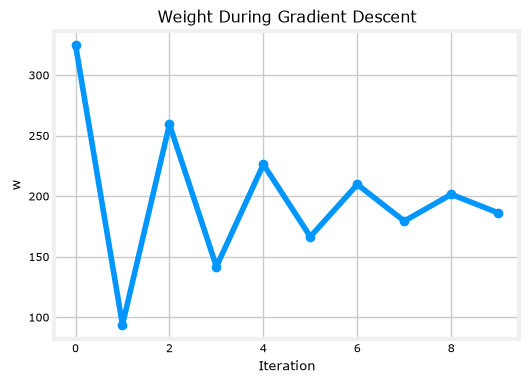

In [20]:
w_hist = [p[0] for p in p_hist]

plt.figure(figsize=(6,4))
plt.plot(w_hist, marker='o')
plt.xlabel("Iteration")
plt.ylabel("w")
plt.title("Weight During Gradient Descent")
plt.grid(True)
plt.show()